<a href="https://colab.research.google.com/github/dapenuela/FP_Growth_Distribucion_Tienda/blob/main/FP_Growth_Seleccionar_CSV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FP-Growth | Canastas y distribución en tienda
**Diego Armando Peñuela Cárdenas · Universidad de Cundinamarca**

Abre este archivo .ipynb en Google Colab y pulsa **Ejecutar todo**. Aparecerá un botón para elegir los CSV de tu computador. Selecciona **un CSV** para un análisis con corte cronológico o **los tres CSV de Bogotá juntos** para conservar la separación original por tiendas. Usa los CSV descomprimidos.

La última celda guarda un ZIP con las reglas, los nombres de los productos, el resumen y una gráfica. Los resultados identifican asociaciones de compra y sirven para proponer exhibiciones. El efecto comercial requiere un piloto en tienda.

In [1]:
import warnings
warnings.filterwarnings('ignore', message=r'.*datetime\.datetime\.utcnow\(\).*deprecated.*',
                        category=DeprecationWarning, module=r'jupyter_client\.session')
from pathlib import Path
from io import BytesIO

def seleccionar_csv():
    from google.colab import files
    print('Elige un CSV o selecciona los tres CSV 01, 02 y 03 al mismo tiempo.')
    return files.upload()

archivos = seleccionar_csv()
if len(archivos) not in (1, 3) or any(Path(nombre).suffix.lower() != '.csv' for nombre in archivos):
    raise ValueError('Selecciona un archivo CSV o los tres CSV descomprimidos (01, 02 y 03).')
print('Archivos recibidos:', ', '.join(archivos))

Elige un CSV o selecciona los tres CSV 01, 02 y 03 al mismo tiempo.


Saving 01_Entrenamiento_10_Tiendas_Bogota.csv to 01_Entrenamiento_10_Tiendas_Bogota.csv
Archivos recibidos: 01_Entrenamiento_10_Tiendas_Bogota.csv


In [2]:
import importlib.util
import subprocess
import sys
if importlib.util.find_spec('mlxtend') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', 'mlxtend==0.23.4'])

import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import fpgrowth
from IPython.display import display

MIN_SOPORTE = 0.02
MIN_CONFIANZA = 0.20
MIN_LIFT = 1.20
MIN_COCOMPRAS = 30
REQUERIDAS = {'tienda','ticket','fecha','sku','cantidad'}

def leer_csv(nombre, contenido):
    datos = pd.read_csv(BytesIO(contenido), encoding='utf-8-sig',
                        usecols=lambda x: x.strip().lower() in REQUERIDAS | {'producto'},
                        dtype='string')
    datos.columns = datos.columns.str.strip().str.lower()
    faltan = REQUERIDAS - set(datos)
    if faltan:
        raise ValueError(f'{nombre}: faltan columnas {", ".join(sorted(faltan))}. Usa el CSV separado por comas.')
    for campo in ['tienda','ticket','sku']:
        datos[campo] = datos[campo].str.strip().replace('', pd.NA)
    datos['fecha'] = pd.to_datetime(datos.fecha, format='mixed', errors='coerce')
    cantidad = pd.to_numeric(datos.cantidad, errors='coerce')
    datos = datos.loc[cantidad.gt(0)].dropna(subset=list(REQUERIDAS))
    if datos.empty:
        raise ValueError(f'{nombre}: no quedaron líneas válidas después de revisar fechas, cantidades y códigos.')
    return datos

leidos = {nombre: leer_csv(nombre, contenido) for nombre,contenido in archivos.items()}
del archivos
catalogo = {}
for df in leidos.values():
    if 'producto' in df:
        catalogo.update(df[['sku','producto']].dropna().drop_duplicates('sku').set_index('sku').producto)

def canastas(datos):
    return (datos.groupby(['tienda','ticket'],sort=False)
            .agg(fecha=('fecha','min'), productos=('sku',lambda x: tuple(dict.fromkeys(x))))
            .reset_index())

if len(leidos) == 3:
    fases = {}
    for prefijo,fase in [('01_','Entrenamiento'),('02_','Validación'),('03_','Prueba final')]:
        candidatos = [df for nombre,df in leidos.items() if Path(nombre).name.startswith(prefijo)]
        if len(candidatos) != 1:
            raise ValueError('Los tres archivos deben comenzar por 01_, 02_ y 03_, respectivamente.')
        fases[fase] = canastas(candidatos[0])
    grupos = [set(df.tienda) for df in fases.values()]
    if len(set.union(*grupos)) != sum(map(len,grupos)):
        raise ValueError('Hay tiendas repetidas entre los tres conjuntos.')
    modo = 'Tres CSV con tiendas independientes'
else:
    cesta = canastas(next(iter(leidos.values()))).sort_values(['fecha','tienda','ticket'],kind='stable')
    n = len(cesta)
    fases = dict(zip(['Entrenamiento','Validación','Prueba final'],
                      [cesta.iloc[:int(n*.70)], cesta.iloc[int(n*.70):int(n*.85)], cesta.iloc[int(n*.85):]]))
    modo = 'Un CSV con corte cronológico 70/15/15 por ticket'
del leidos

for fase, df in fases.items():
    if df.empty:
        raise ValueError(f'No hay tickets en {fase}. Carga un CSV con más transacciones.')
    print(f'{fase}: {len(df):,} tickets · {df.tienda.nunique()} tiendas')
print(modo)

Entrenamiento: 58,799 tickets · 10 tiendas
Validación: 12,601 tickets · 10 tiendas
Prueba final: 12,600 tickets · 10 tiendas
Un CSV con corte cronológico 70/15/15 por ticket


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
from math import ceil
from mlxtend.preprocessing import TransactionEncoder

def matriz(df):
    encoder = TransactionEncoder()
    listas = df.productos.tolist()
    valores = encoder.fit(listas).transform(listas)
    return pd.DataFrame(valores,columns=encoder.columns_)

bases = {fase:matriz(df) for fase,df in fases.items()}
train = bases['Entrenamiento']
if len(train) < MIN_COCOMPRAS:
    raise ValueError(f'Entrenamiento requiere al menos {MIN_COCOMPRAS} tickets con el filtro actual.')
items = fpgrowth(train,min_support=max(MIN_SOPORTE,MIN_COCOMPRAS/len(train)),
                 max_len=2,use_colnames=True)
estad = {fase:(len(m), m.sum().to_dict(), {s:m[s].to_numpy() for s in m})
         for fase,m in bases.items()}
minimos = {f:max(5,ceil(MIN_COCOMPRAS*len(m)/len(train))) for f,m in bases.items()}
minimos['Entrenamiento'] = MIN_COCOMPRAS

def medir(a,b,fase):
    n, conteos, columnas = estad[fase]
    na,nb = conteos.get(a,0),conteos.get(b,0)
    juntos = int(np.count_nonzero(columnas[a] & columnas[b])) if na and nb else 0
    confianza = juntos/na if na else 0
    return juntos/n, confianza, confianza/(nb/n) if nb else 0, juntos

def aprueba(m,fase):
    soporte,confianza,lift,juntos = m
    return soporte >= MIN_SOPORTE and confianza >= MIN_CONFIANZA and lift > MIN_LIFT and juntos >= minimos[fase]

columnas = ['sku_a','sku_b','producto_a','producto_b']
for etiqueta in ('ent','val','prueba'):
    columnas.extend(f'{m}_{etiqueta}' for m in ('soporte','confianza','lift','cocompras'))
columnas += ['pasa_validacion','pasa_prueba']
filas = []
for conjunto in items.itemsets:
    if len(conjunto) != 2:
        continue
    a,b = sorted(conjunto)
    for x,y in [(a,b),(b,a)]:
        ent = medir(x,y,'Entrenamiento')
        if not aprueba(ent,'Entrenamiento'):
            continue
        val = medir(x,y,'Validación')
        ok_val = aprueba(val,'Validación')
        prueba = medir(x,y,'Prueba final') if ok_val else (None,)*4
        filas.append((x,y,catalogo.get(x,x),catalogo.get(y,y),*ent,*val,*prueba,
                      ok_val,ok_val and aprueba(prueba,'Prueba final')))
reglas = pd.DataFrame(filas,columns=columnas)
finales = reglas.loc[reglas.pasa_prueba.astype(bool)].sort_values('cocompras_prueba',ascending=False)
parejas = finales.assign(pareja=[tuple(sorted((a,b))) for a,b in zip(finales.sku_a,finales.sku_b)])
parejas = parejas.drop_duplicates('pareja').drop(columns='pareja')
print(f'Reglas detectadas: {len(reglas)} · validadas: {int(reglas.pasa_validacion.sum())} · estables en prueba: {len(finales)}')
display(parejas[['producto_a','producto_b','cocompras_prueba','lift_prueba']].head(10))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Reglas detectadas: 336 · validadas: 333 · estables en prueba: 330


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,producto_a,producto_b,cocompras_prueba,lift_prueba
122,Avena refrigerada 250 mL,Queso doble crema 200 g,510.0,1.659252
12,Chocolate de mesa 250 g,Mantequilla 125 g,505.0,1.707273
65,Jamón de cerdo 200 g,Kumis 200 g,499.0,1.719250
182,Avena refrigerada 250 mL,Kumis 200 g,494.0,1.560117
132,Avena refrigerada 250 mL,Salchicha 250 g,491.0,1.666815
3,Queso campesino 250 g,Huevos A 6 und,481.0,1.694878
128,Cebolla cabezona 500 g,Papas pastusas 1 kg,480.0,1.631852
8,Queso campesino 250 g,Mantequilla 125 g,479.0,1.695873
59,Queso doble crema 200 g,Jamón de cerdo 200 g,477.0,1.693046
61,Jamón de cerdo 200 g,Avena refrigerada 250 mL,477.0,1.614905


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

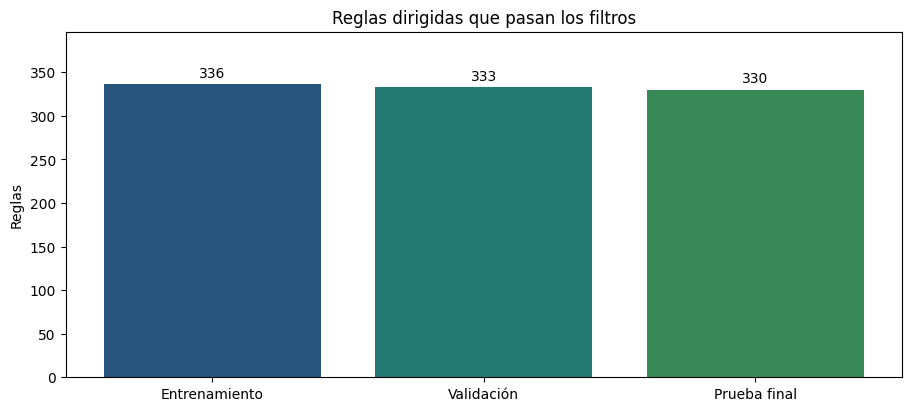

ZIP generado: /content/Evidencias_FP_Growth_Tiendas.zip


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/content/Evidencias_FP_Growth_Tiendas.zip

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [4]:
import matplotlib.pyplot as plt
from zipfile import ZipFile, ZIP_DEFLATED
from datetime import datetime, timezone

out = Path('salidas_tienda')
out.mkdir(exist_ok=True)
reglas.to_csv(out/'reglas_evaluadas.csv',index=False,encoding='utf-8-sig')
parejas.to_csv(out/'parejas_estables_exhibicion.csv',index=False,encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(9,4),layout='constrained')
conteos = [len(reglas),int(reglas.pasa_validacion.sum()),len(finales)]
barras = ax.bar(['Entrenamiento','Validación','Prueba final'],conteos,color=['#26547c','#237a72','#398957'])
ax.bar_label(barras,padding=3)
ax.set(ylim=(0,max(conteos+[1])*1.18),title='Reglas dirigidas que pasan los filtros',ylabel='Reglas')
fig.savefig(out/'reglas_por_etapa.png',dpi=180)
plt.show()

lineas = ['# Evidencia de ejecución de FP-Growth', '',
          f'Fecha UTC: {datetime.now(timezone.utc).isoformat(timespec="seconds")}', modo]
lineas += [f'- {fase}: {len(df):,} tickets; {df.tienda.nunique()} tiendas.' for fase,df in fases.items()]
lineas += [f'- Reglas por etapa: {conteos}.', f'- Parejas estables únicas: {len(parejas)}.',
           f'- Filtros: soporte ≥ {MIN_SOPORTE:.0%}, confianza ≥ {MIN_CONFIANZA:.0%}, lift > {MIN_LIFT:g}.',
           f'- Mínimos de co-compras: {minimos}.',
           'La estabilidad mide asociaciones. El impacto comercial se evalúa en un piloto.']
(out/'resumen_ejecucion.md').write_text(chr(10).join(lineas),encoding='utf-8')
zip_salida = Path('Evidencias_FP_Growth_Tiendas.zip')
with ZipFile(zip_salida,'w',compression=ZIP_DEFLATED) as z:
    for nombre in ['reglas_evaluadas.csv','parejas_estables_exhibicion.csv','reglas_por_etapa.png','resumen_ejecucion.md']:
        z.write(out/nombre,nombre)
print(f'ZIP generado: {zip_salida.resolve()}')
from IPython.display import FileLink
display(FileLink(str(zip_salida)))